In [12]:
# import knihoven
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from uncertainties import ufloat as uf
from uncertainties import unumpy as unp
from pathlib import Path

# path config
downloads_dir = Path.home() / 'Downloads'
# ujistime se, ze slozka existuje (kdyby nahodou ne)
downloads_dir.mkdir(parents=True, exist_ok=True)
# output_path = downloads_dir / 'muj_graf.png'

In [33]:
# definice funkci

# nejistota typu A 
def unc_A(data):
    '''
    Výpočet nejistoty typu A
    data : list nebo numpy array
         měření
    return : float
        nejistota typu A
    '''
    data = np.array(data)
    n = len(data)

    s = np.std(data, ddof=1)
    u_A = s / np.sqrt(n)
    
    return u_A

# nacteni z tabulky
def nacteni_array(df, *list_data, dtype=float):
    return tuple(df[v].dropna().to_numpy(dtype=dtype) for v in list_data)

# nacteni z df do numpy
def df_to_numpy(df, sloupce, dtype=float):
    """
    sloupce: jmeno sloupce (str) nebo seznam jmen (list[str])
    """
    if isinstance(sloupce, str):
        sloupce = [sloupce]

    chybejici = [s for s in sloupce if s not in df.columns]
    if chybejici:
        raise KeyError(f"Chybejici sloupce: {chybejici}")

    data = df[sloupce].to_numpy(dtype=dtype)
    return data[:, 0] if len(sloupce) == 1 else data

# ufloat pro tuple
def tuple_unc_A(*velicina):
    list_velicin = [*velicina]
    return tuple(uf(np.mean(v), unc_A(v)) for v in list_velicin)

In [ ]:
# nacteni google tabuleksach15_proc
sheet_id = '1SR-xU3o3py2D8sSCnXWfbbmhoSYlBci-QvDomAE58Fw'
gid = '0'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_refrakto = pd.read_csv(url)
df_refrakto.dropna()

,destil_n,sach5_n,sach10_n,sach15_n,destil_proc,sach5_proc,sach10_proc,sach15_proc
0,1.3312,1.3394,1.3464,1.3538,-1.5,4.4,9.2,13.7
1,1.3310,1.3392,1.3468,1.3537,-1.6,4.4,9.3,13.6
2,1.3314,1.3397,1.3462,1.3538,-1.4,4.5,9.1,13.6


In [ ]:
# refrakto a polari
destil_n, sach5_n, sach10_n, sach15_n = (df_refrakto[c].dropna().to_numpy() for c in ['destil_n', 'sach5_n', 'sach10_n', 'sach15_n'])
destil_n, sach5_n, sach10_n, sach15_n = (uf(np.mean(v), unc_A(v)) for v in [destil_n, sach5_n, sach10_n, sach15_n])

destil_proc, sach5_proc, sach10_proc, sach15_proc = (df_refrakto[c].dropna().to_numpy() for c in ['destil_proc', 'sach5_proc', 'sach10_proc', 'sach15_proc'])
destil_proc, sach5_proc, sach10_proc, sach15_proc = (uf(np.mean(v), unc_A(v)) for v in [destil_proc, sach5_proc, sach10_proc, sach15_proc])




In [18]:
# nacteni google tabuleksach15_proc
sheet_id = '1SR-xU3o3py2D8sSCnXWfbbmhoSYlBci-QvDomAE58Fw'
gid = '415661874'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_polari = pd.read_csv(url)
df_polari.dropna()

,Nulová poloha (°),Roztok 15 % – odečtený úhel (°),Roztok 10 % – odečtený úhel (°),Roztok 5 % – odečtený úhel (°)
0,-0.05,10.50,6.90,3.55
1,-0.05,10.40,6.80,3.65
2,0.00,10.40,6.85,3.55
3,0.00,10.35,6.80,3.65
4,0.00,10.35,6.85,3.70


In [40]:
nazvy = ['Nulová poloha (°)', 'Roztok 15 % – odečtený úhel (°)', 'Roztok 10 % – odečtený úhel (°)', 'Roztok 5 % – odečtený úhel (°)']
nul_poloha, uhel15, uhel10, uhel5 = df_to_numpy(df_polari, nazvy).T
nul_poloha, uhel15, uhel10, uhel5 = tuple_unc_A(nul_poloha, uhel15, uhel10, uhel5)

d = 1 # v dm
konc = np.array([sach5_proc, sach10_proc, sach15_proc])
alpha = np.array([uhel5, uhel10, uhel15])

spec_stac = (100*alpha)/(d*konc)
spec_stac

array([81.65413533834587+/-0.9136931021736687,
       74.3478260869565+/-0.508961873073624,
       76.28361858190709+/-0.27411344994279485], dtype=object)

In [50]:
# nacteni google tabuleksach15_proc
sheet_id = '1SR-xU3o3py2D8sSCnXWfbbmhoSYlBci-QvDomAE58Fw'
gid = '2139253552'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_malus = pd.read_csv(url)
#df_malus.dropna()

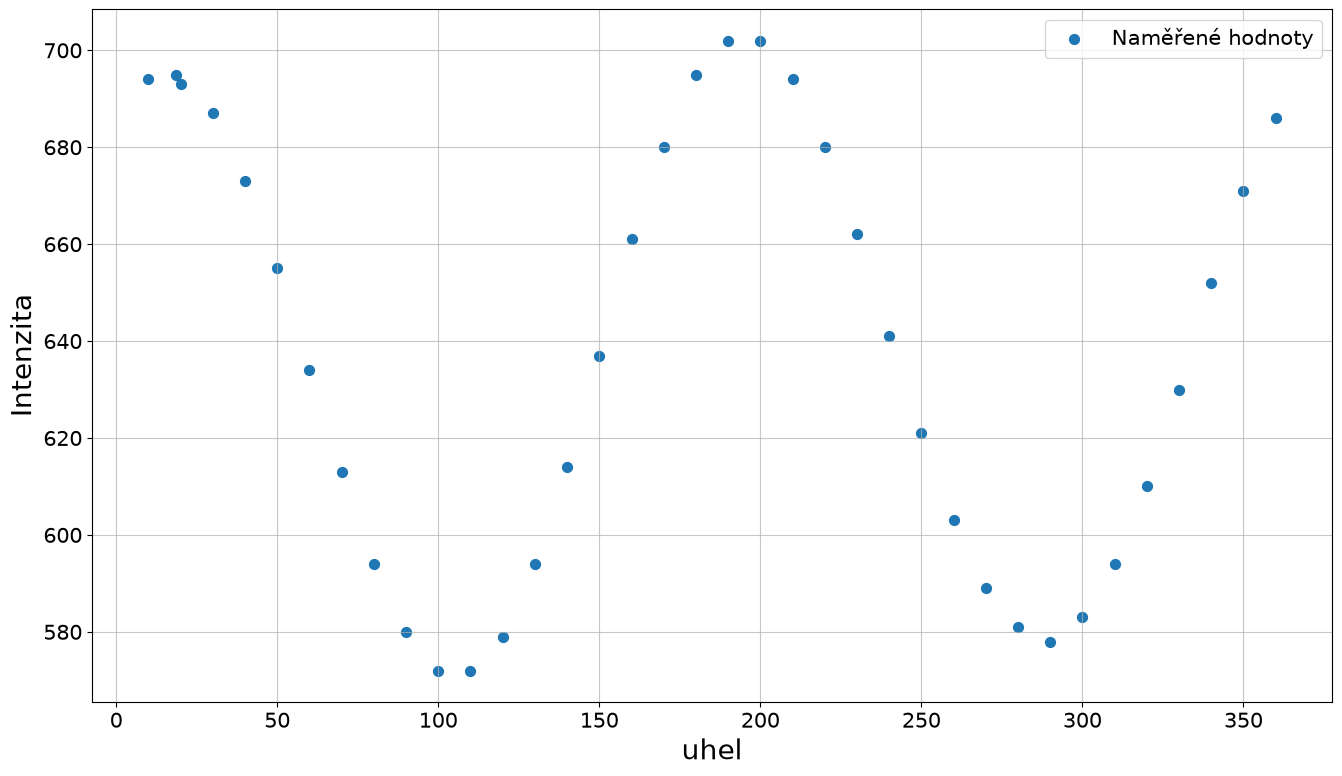

In [49]:
names_malus = ['Úhel otočení polarizátoru (°)', 'bílé světlo muA', 'filtr 10 nA']
uhel_pol, bile, zelene = df_to_numpy(df_malus, names_malus).T

fig, ax = plt.subplots(figsize=(16, 9))
ax.set_ylabel(r'Intenzita', fontsize=20)
ax.set_xlabel(r'uhel', fontsize=20)
ax.scatter(uhel_pol, bile, label='Naměřené hodnoty', s=50)
ax.tick_params(labelsize=15)
ax.grid(True, alpha=0.7)
ax.legend(fontsize=15)
plt.savefig(downloads_dir / 'malus.pdf', dpi=300, bbox_inches='tight')